# Choosing the head/tail split with `best_split`

`HQSMPO` splits the chain of $K$ dressed Pauli rotations at a cut $k$: the
*head*, rotations $[0, k)$, acts on the initial state, and the *tail*,
rotations $[k, K)$, is folded into the observable as an MPO. Classically
(`method="simulation"`) the head is a truncated MPS and the expectation value
is $\langle \mathrm{head}_k | O_k | \mathrm{head}_k \rangle$.

At a fixed bond dimension $\chi$ the cut decides *where* the truncation
happens. Two extremes are always available:

- $k = 0$: every rotation is folded into the observable (Heisenberg picture),
  so only the tail MPO is truncated;
- $k = K$: every rotation is applied to the state, so only the head MPS is
  truncated. This is exactly what a plain `HSMPO` computes at the same $\chi$.

A cut in between shares the entanglement between state and operator, and can
be far more accurate than either extreme. `split_scan` evaluates every cut in
one pass; `best_split` picks one. It offers two criteria:

1. **`truncation_score`** (the default, no extra cost): how much weight the
   two truncations discarded,
   $\varepsilon_\mathrm{tail}(k) + \lVert c\rVert_1 \sqrt{1 - F_\mathrm{head}(k)}$.
   It measures *how much* was truncated, not how much that moves
   $\langle O\rangle$, so it can misrank cuts.
2. **`reference=True`** (one extra scan): repeat the scan with a looser
   truncation, $2\chi$ and SVD cutoff $10^{-12}$ (`reference_scan`), and pick
   the cut whose value moves least,
   $\min_k |v_\chi(k) - v_\mathrm{ref}(k)|$. Where the reference is accurate,
   this distance *is* the error of cut $k$.

Throughout, the instance is built with `light_cone=True`: each Pauli term of
the observable is folded only with the tail rotations it can see. The others
cancel exactly, but folding them anyway grows the MPO and gets them truncated.
Skipping them makes both scans cheaper and, on shallow circuits, much more
accurate (see below).

This notebook shows a case where the two criteria disagree, and checks against
the exact state vector which one to trust.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from qibo import hamiltonians, symbols

from mpstab import HSMPO
from mpstab.evolutors.hqsmpo import HQSMPO
from mpstab.models.ansatze import HardwareEfficientBrickwork, KickedIsing, TrotterIsing

BLUE, ORANGE, GREEN, GRAY = "#2a78d6", "#eb6834", "#1f9e6e", "#8a8a86"
FLOOR = 1e-16  # plotting floor for errors at rounding level
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "lines.linewidth": 2,
    }
)

/home/robdilauro/tesi/mpstab/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Setup

A kicked Ising circuit on 10 qubits, 5 steps ($K = 100$ dressed rotations),
and the transverse-field Ising Hamiltonian

$$
H = \sum_{i} Z_i Z_{i+1} + 0.7 \sum_i X_i ,
$$

at bond dimension $\chi = 4$ for both the head MPS and the tail MPO.

Ten qubits are small enough for qibo's state vector to give the exact value.
We use it only to *check* the choices, never to make them. (An untruncated
`HQSMPO` is not a safe exact reference: the default SVD cutoff, $10^{-10}$,
still truncates, and over a long fold it adds up to errors well above
$10^{-10}$.)

In [2]:
nqubits, chi = 10, 4


def tfim(n, h=0.7):
    form = sum(symbols.Z(i) * symbols.Z(i + 1) for i in range(n - 1))
    form += h * sum(symbols.X(i) for i in range(n))
    return hamiltonians.SymbolicHamiltonian(form, nqubits=n)


def exact_value(ansatz, observable):
    # qibo state vector: no truncation anywhere
    return float(np.real(observable.expectation_from_state(ansatz.circuit().state())))


# the circuit's angles are a random draw, see the robustness section below
ansatz = KickedIsing(nqubits=nqubits, n_steps=5, theta_h=0.8459721981904618, theta_z=0.7294965609839984)
hamiltonian = tfim(nqubits)
exact = exact_value(ansatz, hamiltonian)
print(f"Exact <H> = {exact:.12f}")

[Qibo 0.3.6|INFO|2026-11-25 11:37:17]: Using numpy backend on /CPU:0


Exact <H> = 2.505470619330


## Scanning every cut

`split_scan` builds the head forwards once, storing the MPS at each cut, and
folds each term's tail backwards once, contracting with the stored head
whenever it reaches a cut. `reference_scan` does the same at $2\chi$ and a
lower SVD cutoff, leaving `hs` untouched. Both follow the instance's
`light_cone`, and both can be handed to `best_split`, so nothing is computed
twice.

In [3]:
hs = HQSMPO(ansatz, max_bond_dimension=chi, light_cone=True, progress=False)

start = time.perf_counter()
scan = hs.split_scan(hamiltonian)
t_scan = time.perf_counter() - start
start = time.perf_counter()
reference = hs.reference_scan(hamiltonian)
t_ref = time.perf_counter() - start
print(f"{len(scan)} cuts: scan {t_scan:.1f} s, reference scan {t_ref:.1f} s")

by_score = hs.best_split(scan=scan)
by_reference = hs.best_split(scan=scan, reference=reference)

K = len(scan) - 1
cuts = np.array([p.cut_index for p in scan])
values = np.array([p.result.value for p in scan])
ref_values = np.array([p.result.value for p in reference])
true_error = np.abs(values - exact)
score = np.array([p.truncation_score for p in scan])
distance = np.abs(values - ref_values)
print(f"K = {K}; truncation_score picks cut {by_score.cut_index}, reference picks cut {by_reference.cut_index}")

101 cuts: scan 8.6 s, reference scan 9.2 s
K = 100; truncation_score picks cut 75, reference picks cut 67


The last cut is the plain `HSMPO` result at the same $\chi$: as a sanity
check, the two agree.

In [4]:
hsmpo_value = float(np.real(HSMPO(ansatz, max_bond_dimension=chi, progress=False).expectation(hamiltonian)))
print(f"HSMPO (chi={chi}):  {hsmpo_value:.12f}")
print(f"split at cut K:   {values[K]:.12f}")

HSMPO (chi=4):  2.568202356636
split at cut K:   2.568202356636


Now compare the two `best_split` choices with the fixed cuts one might
pick without a scan, and with the cut that has the smallest true error,
*best cut (exact)*, which needs the exact value.

In [5]:
choices = {
    "cut 0 (all in the tail MPO)": 0,
    "cut K/2": K // 2,
    "cut K (plain HSMPO)": K,
    "best_split, truncation_score": by_score.cut_index,
    "best_split, reference=True": by_reference.cut_index,
    "best cut (exact)": int(np.argmin(true_error)),
}
print(f"{'choice':<32}{'cut':>5}{'|error|':>12}")
for name, k in choices.items():
    print(f"{name:<32}{k:>5}{true_error[k]:>12.2e}")

choice                            cut     |error|
cut 0 (all in the tail MPO)         0    1.46e+00
cut K/2                            50    1.85e-01
cut K (plain HSMPO)               100    6.27e-02
best_split, truncation_score       75    6.27e-02
best_split, reference=True         67    2.88e-05
best cut (exact)                   67    2.88e-05


The reference lands on the best cut (exact), about three orders of
magnitude below the plain `HSMPO`. `truncation_score` picks a cut on the
plateau that ends at the plain `HSMPO`, with the same error.

The plot shows the whole scan: the true error (blue), the distance to the
reference that `reference=True` minimises (green), and `truncation_score`
(orange). The green curve follows the blue one closely: where the reference is
much more accurate than $\chi$, $|v_\chi - v_\mathrm{ref}| \approx
|v_\chi - v_\mathrm{exact}|$. `truncation_score` sits orders of magnitude above
both and is nearly flat: it misses the narrow dip around the best cut and
bottoms out on the plateau before the plain `HSMPO`. The cuts where the least weight is
discarded are not always the ones where $\langle H\rangle$ moves least.

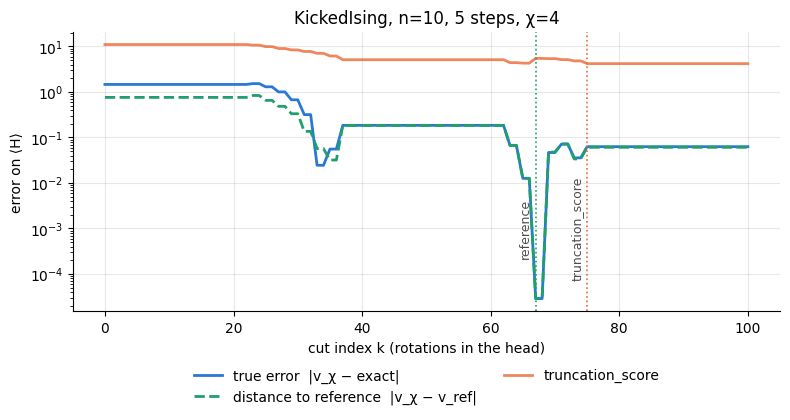

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.semilogy(cuts, np.maximum(true_error, FLOOR), "-", color=BLUE, label="true error  |v_χ − exact|")
ax.semilogy(cuts, np.maximum(distance, FLOOR), "--", color=GREEN, label="distance to reference  |v_χ − v_ref|")
ax.semilogy(cuts, np.maximum(score, FLOOR), "-", color=ORANGE, alpha=0.8, label="truncation_score")
for k, color, text in [(by_reference.cut_index, GREEN, "reference"), (by_score.cut_index, ORANGE, "truncation_score")]:
    ax.axvline(k, color=color, ls=":", lw=1.2)
    ax.annotate(text, (k, 1e-3), textcoords="offset points", xytext=(-12, 0), fontsize=9, color="0.3", rotation=90, va="center")
ax.set_xlabel("cut index k (rotations in the head)")
ax.set_ylabel("error on ⟨H⟩")
ax.set_title(f"KickedIsing, n={nqubits}, 5 steps, χ={chi}")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
fig.tight_layout()
plt.show()

## Why the reference needs a lower cutoff too

Doubling $\chi$ alone is not enough. The SVD cutoff also truncates, and the
same cutoff at $\chi$ and $2\chi$ discards the same small Schmidt values, so
those errors cancel in $|v_\chi - v_{2\chi}|$ and stay invisible. On long
circuits, Trotter in particular, they add up to $10^{-6}$ to $10^{-4}$ near
cut 0, and a reference with the default cutoff then prefers exactly those cuts.
`reference_scan` therefore lowers the cutoff to $10^{-12}$ as well
(`svd_cutoff=` changes it, `bond_factor=` the bond multiplier). The cutoff of
the scan being ranked stays as it is: it keeps the networks small, and the
reference measures its effect too.

## What the light cone adds

On the kicked Ising circuit above, five steps are enough for every term's light
cone to cover the whole chain, so `light_cone=True` only saves time. On a
shallow circuit the cones are narrow. Take one layer of a brickwork ansatz:
each term of $H$ sees only a few rotations, and folded alone they fit in
$\chi = 4$. Without the light cone, the rotations outside the cone are folded
too and truncated, and no cut is accurate.

In [7]:
np.random.seed(0)
shallow = HardwareEfficientBrickwork(nqubits=nqubits, nlayers=1)
exact_shallow = exact_value(shallow, hamiltonian)

print(f"{'light_cone':<12}{'chosen cut':>11}{'|error|':>12}{'time (s)':>10}")
for light_cone in (False, True):
    hs_shallow = HQSMPO(shallow, max_bond_dimension=chi, light_cone=light_cone, progress=False)
    start = time.perf_counter()
    choice = hs_shallow.best_split(hamiltonian, reference=True)
    elapsed = time.perf_counter() - start
    print(f"{str(light_cone):<12}{choice.cut_index:>11}{abs(choice.result.value - exact_shallow):>12.2e}{elapsed:>10.1f}")

light_cone   chosen cut     |error|  time (s)


False                 1    5.13e-03      13.2


True                  0    2.66e-15      10.1


With the light cone the chosen cut is exact to machine precision. Without
it, even the best cut is off by about $5 \times 10^{-3}$. The reference picks
well in both cases: the light cone changes what the scan can reach, not how
the cut is chosen.

## How robust is the choice?

One circuit could be a lucky draw. We repeat the comparison on brickwork,
kicked Ising and Trotter circuits with $\chi = 4$ and $8$, for the local
observable $Z_5$, which is cheap to scan, with `light_cone=True`. This takes
a couple of minutes.

In [8]:
def circuits():
    for nlayers in (1, 2):
        for seed in range(4):
            np.random.seed(seed)
            yield "brickwork", HardwareEfficientBrickwork(nqubits=nqubits, nlayers=nlayers)
    rng = np.random.default_rng(0)
    for steps in (4, 5, 6):
        for _ in range(3):
            theta_h, theta_z = rng.uniform(0.3, 1.2), rng.uniform(0.0, 1.0)
            yield "kicked", KickedIsing(nqubits=nqubits, n_steps=steps, theta_h=theta_h, theta_z=theta_z)
    for steps in (6, 8):
        for dt in (0.2, 0.3):
            yield "trotter", TrotterIsing(nqubits=nqubits, n_steps=steps, dt=dt)


z_mid = "I" * (nqubits // 2) + "Z" + "I" * (nqubits - nqubits // 2 - 1)
z_mid_qibo = hamiltonians.SymbolicHamiltonian(symbols.Z(nqubits // 2), nqubits=nqubits)
NOISE = 1e-10  # errors below this are rounding: treat them as equal

rows = []
start = time.perf_counter()
for family, circuit in circuits():
    exact = exact_value(circuit, z_mid_qibo)
    for bond in (4, 8):
        hs = HQSMPO(circuit, max_bond_dimension=bond, light_cone=True, progress=False)
        scan = hs.split_scan(z_mid)
        reference = hs.reference_scan(z_mid)
        error = np.array([abs(p.result.value - exact) for p in scan])
        if error.max() < NOISE:
            continue  # every cut exact: nothing to choose
        best = max(error.min(), NOISE)
        ratio = lambda k: max(error[k], NOISE) / best  # noqa: E731
        rows.append(
            {
                "family": family,
                "truncation_score": ratio(hs.best_split(scan=scan).cut_index),
                "reference": ratio(hs.best_split(scan=scan, reference=reference).cut_index),
                "plain HSMPO": ratio(len(scan) - 1),
            }
        )
print(f"{len(rows)} cases in {time.perf_counter() - start:.0f} s")

strategies = ["truncation_score", "reference", "plain HSMPO"]
print(f"{'criterion':<18}{'<= 2x best':>12}{'<= 10x best':>13}{'> 100x best':>13}{'worst':>10}")
for s in strategies:
    r = np.array([row[s] for row in rows])
    print(f"{s:<18}{(r <= 2).sum():>9}/{len(r)}{(r <= 10).sum():>10}/{len(r)}{(r > 100).sum():>10}/{len(r)}{r.max():>10.1e}")

42 cases in 63 s
criterion           <= 2x best  <= 10x best  > 100x best     worst
truncation_score         34/42        39/42         0/42   1.5e+01
reference                42/42        42/42         0/42   1.2e+00
plain HSMPO               4/42         8/42        29/42   1.5e+09


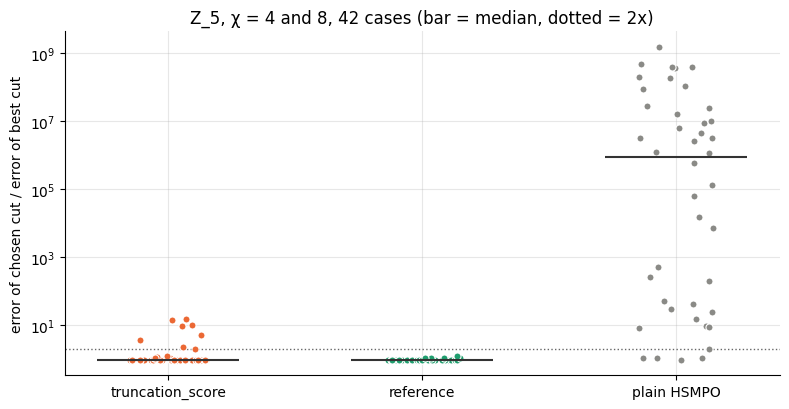

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.2))
jitter = np.random.default_rng(0)
colors = {"truncation_score": ORANGE, "reference": GREEN, "plain HSMPO": GRAY}
for i, s in enumerate(strategies):
    y = np.array([row[s] for row in rows])
    ax.scatter(i + jitter.uniform(-0.15, 0.15, len(y)), y, s=26, color=colors[s], edgecolor="white", linewidth=0.8, zorder=3)
    ax.hlines(np.median(y), i - 0.28, i + 0.28, color="0.2", lw=1.5, zorder=4)
ax.set_yscale("log")
ax.axhline(2, color="0.4", ls=":", lw=1)
ax.set_xticks(range(len(strategies)), strategies)
ax.set_ylabel("error of chosen cut / error of best cut")
ax.set_title(f"Z_5, χ = 4 and 8, {len(rows)} cases (bar = median, dotted = 2x)")
fig.tight_layout()
plt.show()

On $Z_5$ the reference picks a cut within 2x of the best one in every
case; `truncation_score` mostly does too, but misses by up to ~15x, and the
plain `HSMPO` is often many orders of magnitude worse.

The same comparison with the Hamiltonian $H$ as well, 84 cases in all
(10 qubits, $\chi = 4$ and $8$), with and without the light cone. Each chosen
cut's error is divided by the lowest error any cut reaches in either scan;
errors below $10^{-10}$ are treated as equal:

| criterion | $\le 2\times$ best | $\le 10\times$ best | $> 100\times$ best | worst |
|---|---|---|---|---|
| `reference=True`, `light_cone=True` | 80 / 84 | 84 / 84 | 0 | 7.4x |
| `reference=True` | 72 / 84 | 78 / 84 | 5 | ~4e8x |
| `truncation_score`, `light_cone=True` | 60 / 84 | 75 / 84 | 2 | ~2200x |
| `truncation_score` | 56 / 84 | 70 / 84 | 7 | ~1e9x |
| plain `HSMPO` (cut $K$) | 10 / 84 | 23 / 84 | 47 | ~8e9x |

Without the light cone, the reference's large misses are all shallow brickwork
circuits like the one above: it picks the best cut *of its scan*, but that scan
cannot reach what the light cone reaches. A reference at $2\chi$ with the
default cutoff does much worse, up to ~6e5x off, mostly on Trotter circuits.
Neither adding the reference's own `truncation_score` to the distance nor
computing the reference only on the top cuts by `truncation_score` improved
on the plain distance.

## Takeaways

- The best cut depends on the circuit, the observable and $\chi$; neither
  extreme is a safe default, and the plain `HSMPO` is the $k = K$ extreme.
- `best_split(observable, reference=True)` on an instance with
  `light_cone=True` is the reliable choice: within 7.4x of the best cut in
  all 84 benchmark cases, with no exact value needed.
- Its cost is one `split_scan` at $\chi$ plus one at $2\chi$ (the reference),
  so the reference costs as much as a scan at twice the bond. How much that
  is depends on whether the bond cap is reached. Measured with
  `light_cone=True`, $H$ as above:

  | circuit | $\chi$ | scan | reference | `best_split(reference=True)` vs scan alone |
  |---|---|---|---|---|
  | brickwork, 2 layers, $n = 24$ | 4 to 16 | 80 s | 80 s | 2.0x |
  | kicked Ising, 4 steps, $n = 24$ | 4 to 128 | 60 s | 60 s | 2.0x |
  | kicked Ising, 12 steps, $n = 16$ | 8 | 84 s | 112 s | 2.3x |
  | kicked Ising, 12 steps, $n = 16$ | 64 | 285 s | 551 s | 2.9x |

  In shallow circuits the bond never reaches $\chi$, the scan time is set by
  the number of folds ($\approx T K$ for $T$ Pauli terms and $K$ rotations),
  and the reference costs the same as the scan. Once the cap is reached,
  contractions grow as $\chi^3$, so at large $\chi$ the reference can
  approach $8\times$ the scan. It also keeps one head MPS per cut at $2\chi$,
  about $4\times$ the memory of the scan's heads.
- `best_split(observable)` (`truncation_score`) costs nothing extra and is a
  reasonable first guess, but it ranks discarded weight, not error.
- `light_cone=True` never made the choice worse in the benchmark, made both
  scans about 20% cheaper, and on shallow circuits turned errors of
  $10^{-3}$ to $10^{-2}$ into exact results. Set it on the instance, so that
  `expectation_at_cut` later folds the chosen cut the same way.
- On hardware the head runs exactly, so these classical criteria rank only
  part of the error. Pass a custom `key` to trade the tail truncation against
  what the device pays, e.g.
  `key=lambda p: p.result.truncation_l2 + w * hs.resynthesize_head(p.cut_index).n_two_qubit_gates`.